In [8]:
import sys
import pandas as pd
import numpy as np

print("Python executable:", sys.executable)
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)

Python executable: c:\Users\giaco\Documents\progetto_python\.venv\Scripts\python.exe
Pandas: 3.0.5
NumPy: 2.4.6


In [47]:

print("Loading datasets...")

recipes = pd.read_csv('data/RAW_recipes.csv')
interactions = pd.read_csv('data/RAW_interactions.csv')

print(f"Total recipes loaded: {len(recipes):,}")
print(f"Total interactions loaded: {len(interactions):,}")

# Referential integrity
interactions = interactions[interactions['recipe_id'].isin(recipes['id'])].copy()

print(f"Consistent interactions after filtering: {len(interactions):,}")

Loading datasets...
Total recipes loaded: 231,637
Total interactions loaded: 1,132,367
Consistent interactions after filtering: 1,132,367


In [11]:
print(interactions.head())
print(interactions.dtypes)
print(interactions.isna().sum())
print(interactions["rating"].value_counts().sort_index())

   user_id  recipe_id        date  rating  \
0    38094      40893  2003-02-17       4   
1  1293707      40893  2011-12-21       5   
2     8937      44394  2002-12-01       4   
3   126440      85009  2010-02-27       5   
4    57222      85009  2011-10-01       5   

                                              review  
0  Great with a salad. Cooked on top of stove for...  
1  So simple, so delicious! Great for chilly fall...  
2  This worked very well and is EASY.  I used not...  
3  I made the Mexican topping and took it to bunk...  
4  Made the cheddar bacon topping, adding a sprin...  
user_id      int64
recipe_id    int64
date           str
rating       int64
review         str
dtype: object
user_id        0
recipe_id      0
date           0
rating         0
review       169
dtype: int64
rating
0     60847
1     12818
2     14123
3     40855
4    187360
5    816364
Name: count, dtype: int64


In [12]:
print("Null values in Recipes:")
print(recipes.isnull().sum())

print("\nNull valuesin Interactions:")
print(interactions.isnull().sum())

Null values in Recipes:
name                 1
id                   0
minutes              0
contributor_id       0
submitted            0
tags                 0
nutrition            0
n_steps              0
steps                0
description       4979
ingredients          0
n_ingredients        0
dtype: int64

Null valuesin Interactions:
user_id        0
recipe_id      0
date           0
rating         0
review       169
dtype: int64


In [13]:
display(recipes.describe()) 
display(interactions.describe())

,id,minutes,contributor_id,n_steps,n_ingredients
count,231637.000000,2.316370e+05,2.316370e+05,231637.000000,231637.000000
mean,222014.708984,9.398546e+03,5.534885e+06,9.765499,9.051153
std,141206.635626,4.461963e+06,9.979141e+07,5.995128,3.734796
min,38.000000,0.000000e+00,2.700000e+01,0.000000,1.000000
25%,99944.000000,2.000000e+01,5.690500e+04,6.000000,6.000000
50%,207249.000000,4.000000e+01,1.736140e+05,9.000000,9.000000
75%,333816.000000,6.500000e+01,3.982750e+05,12.000000,11.000000
max,537716.000000,2.147484e+09,2.002290e+09,145.000000,43.000000


,user_id,recipe_id,rating
count,1.132367e+06,1.132367e+06,1.132367e+06
mean,1.384291e+08,1.608972e+05,4.411016e+00
std,5.014269e+08,1.303987e+05,1.264752e+00
min,1.533000e+03,3.800000e+01,0.000000e+00
25%,1.354700e+05,5.425700e+04,4.000000e+00
50%,3.309370e+05,1.205470e+05,5.000000e+00
75%,8.045500e+05,2.438520e+05,5.000000e+00
max,2.002373e+09,5.377160e+05,5.000000e+00


In [14]:
# Col with (NaN) description (head)
recipes_without_description = recipes[recipes['description'].isna()]

display(recipes_without_description.head())

,name,id,minutes,contributor_id,submitted,tags,nutrition,n_steps,steps,description,ingredients,n_ingredients
5,apple a day milk shake,5289,0,1533,1999-12-06,"['15-minutes-or-less', 'time-to-make', 'course...","[160.2, 10.0, 55.0, 3.0, 9.0, 20.0, 7.0]",4,"['combine ingredients in blender', 'cover and ...",NaN,"['milk', 'vanilla ice cream', 'frozen apple ju...",4
8,bananas 4 ice cream pie,70971,180,102353,2003-09-10,"['weeknight', 'time-to-make', 'course', 'main-...","[4270.8, 254.0, 1306.0, 111.0, 127.0, 431.0, 2...",8,"['crumble cookies into a 9-inch pie plate , or...",NaN,"['chocolate sandwich style cookies', 'chocolat...",6
74,philly waldorf salad,5060,60,1534,1999-12-01,"['60-minutes-or-less', 'time-to-make', 'course...","[180.7, 22.0, 29.0, 3.0, 6.0, 33.0, 3.0]",4,"['combine softened cream cheese , orange juice...",NaN,"['philadelphia cream cheese', 'orange juice', ...",7
76,pizza stuffed potato,52443,25,1533,2003-01-28,"['30-minutes-or-less', 'time-to-make', 'course...","[183.3, 12.0, 9.0, 15.0, 21.0, 23.0, 6.0]",8,"['preheat oven to 450 degrees', 'cut potato in...",NaN,"['baking potato', 'mozzarella cheese', 'tomato...",7
99,the woiks dilly burgers,34930,32,23302,2002-07-24,"['bacon', '60-minutes-or-less', 'time-to-make'...","[449.2, 50.0, 16.0, 19.0, 58.0, 67.0, 2.0]",8,"['in a bowl , mix together the ground beef , m...",NaN,"[""mccormick's montreal brand steak seasoning"",...",9


In [15]:
# Missing name recipe
nameless_recipe = recipes[recipes['name'].isna()]
display(nameless_recipe)

,name,id,minutes,contributor_id,submitted,tags,nutrition,n_steps,steps,description,ingredients,n_ingredients
721,NaN,368257,10,779451,2009-04-27,"['15-minutes-or-less', 'time-to-make', 'course...","[1596.2, 249.0, 155.0, 0.0, 2.0, 112.0, 14.0]",6,"['in a bowl , combine ingredients except for o...",-------------,"['lemon', 'honey', 'horseradish mustard', 'gar...",10


In [16]:
# Extract and display the full steps and ingredients for this recipe
target_recipe = recipes.loc[recipes['id'] == 368257]
print("Ingredients:", target_recipe['ingredients'].values[0])
print("Steps:", target_recipe['steps'].values[0])

Ingredients: ['lemon', 'honey', 'horseradish mustard', 'garlic clove', 'dried parsley', 'dried basil', 'dried thyme', 'garlic salt', 'black pepper', 'olive oil']
Steps: ['in a bowl , combine ingredients except for olive oil', 'slowly whisk inches', 'olive oil until thickened', 'great with field greens', 'makes about 2 / 3', 'cup dressing']


In [17]:
# Naming and describing (id: 368257) 
recipes.loc[recipes['id'] == 368257, 'name'] = 'Honey Lemon Mustard Cup Dressing'
recipes.loc[recipes['id'] == 368257, 'description'] = 'Honey lemon mustard cup dressing'

In [18]:
# Fill missing text reviews with an empty string
interactions['review'] = interactions['review'].fillna('')

# Check missing values again to confirm it's completely clean
print("Missing values in interactions dataset:")
print(interactions.isna().sum())

Missing values in interactions dataset:
user_id      0
recipe_id    0
date         0
rating       0
review       0
dtype: int64


In [19]:
import ast

# Convert string representation of nutrition values into python lists
recipes['nutrition_list'] = recipes['nutrition'].apply(ast.literal_eval)

# Compute total nutritional value to identify potential data entry errors
recipes['nutrition_sum'] = recipes['nutrition_list'].apply(sum)

# Filter recipes with zero total nutrition
zero_nutrition_recipes = recipes[recipes['nutrition_sum'] == 0]

print(f"Anomalous recipes (Zero total nutrition): {len(zero_nutrition_recipes)}")

Anomalous recipes (Zero total nutrition): 0


In [20]:
# Drop temporary nutrition columns 
recipes = recipes.drop(columns=['nutrition_list', 'nutrition_sum'])

In [21]:
# Convert the column to datetime objects
recipes['submitted'] = pd.to_datetime(recipes['submitted'])

# Chronological boundaries of the dataset
oldest_recipe = recipes['submitted'].min()
newest_recipe = recipes['submitted'].max()
print(f"Oldest recipe: {oldest_recipe.date()}")
print(f"Newest recipe: {newest_recipe.date()}")

Oldest recipe: 1999-08-06
Newest recipe: 2018-12-04


In [22]:
# Check data and conversion
print(f"Data type of 'submitted': {recipes['submitted'].dtype}")

failed_dates = recipes['submitted'].isna().sum()
print(f"Number of failed date conversions: {failed_dates}")

Data type of 'submitted': datetime64[us]
Number of failed date conversions: 0


In [23]:
# Show the exact raw text inside the 'tags' column for the first recipe
print("Raw text format:")
print(recipes['tags'].iloc[1:5])

Raw text format:
1    ['30-minutes-or-less', 'time-to-make', 'course...
2    ['time-to-make', 'course', 'preparation', 'mai...
3    ['60-minutes-or-less', 'time-to-make', 'course...
4    ['weeknight', 'time-to-make', 'course', 'main-...
Name: tags, dtype: str


In [24]:
from collections import Counter
import ast

# Checking for Python list
if 'tags_list' not in recipes.columns:
    recipes['tags_list'] = recipes['tags'].apply(ast.literal_eval)

# Put all tags in a list
all_tags = [tag for sublist in recipes['tags_list'] for tag in sublist]

# Counting tags
tag_counts = Counter(all_tags)

# Top common and least common
print(" Most common tags: ")
for tag, count in tag_counts.most_common(5):
    print(f"{tag}: {count}")

print("\n Least common tags: ")
for tag, count in tag_counts.most_common()[-5:]:
    print(f"{tag}: {count}")

 Most common tags: 
preparation: 230546
time-to-make: 225326
course: 218148
main-ingredient: 170446
dietary: 165091

 Least common tags: 
chicken-stews: 1
chicken-stew: 1
Throw the ultimate fiesta with this sopaipillas recipe from Food.com.: 1
roast-beef-main-dish: 1
roast-beef-comfort-food: 1


In [25]:
# Checking for zero tags recipes
recipes['n_tags'] = recipes['tags_list'].apply(len)
empty_tags_recipes = recipes[recipes['n_tags'] == 0]
print(f"Recipes with zero tags: {len(empty_tags_recipes)}")

Recipes with zero tags: 0


In [26]:
import numpy as np

# Isolate recipes with actual steps to avoid division by zero
valid_steps_recipes = recipes[recipes['n_steps'] > 0].copy()

# Calculate the ratio (average time step duration)
valid_steps_recipes['minutes_per_step'] = valid_steps_recipes['minutes'] / valid_steps_recipes['n_steps']

# Define tags that require long passive waiting times
passive_keywords = ['marinade', 'marinades', 'slow-cook', 'crock-pot', 'freezer', 
                    'sourdough', 'fermentation', 'canning', 'dehydrator']

# Function to check for passive tags
def has_passive_tags(tag_list):
    return any(keyword in tag_list for keyword in passive_keywords)

valid_steps_recipes['is_passive_cooking'] = valid_steps_recipes['tags_list'].apply(has_passive_tags)

# Split the dataset to compare
standard_recipes = valid_steps_recipes[~valid_steps_recipes['is_passive_cooking']]
passive_recipes = valid_steps_recipes[valid_steps_recipes['is_passive_cooking']]

# Print the median ratio (median > mean)
print(f"Standard recipes - Median minutes per step: {standard_recipes['minutes_per_step'].median():.1f}")
print(f"Passive recipes - Median minutes per step: {passive_recipes['minutes_per_step'].median():.1f}")

Standard recipes - Median minutes per step: 4.1
Passive recipes - Median minutes per step: 6.0


In [27]:
# Identify recipes that claim 0 minutes but actually have preparation steps
zero_minutes_anomalies = recipes[(recipes['minutes'] == 0) & (recipes['n_steps'] > 0)]

# Identify long recipes (more than 24 hours)
over_one_day = recipes[recipes['minutes'] > 1440]

# Identify extreme outliers (more than 30 days / 43200 minutes)
over_one_month = recipes[recipes['minutes'] > 43200]

print(f"Anomalies (0 minutes but >0 steps): {len(zero_minutes_anomalies)}")
print(f"Long recipes (> 24 hours): {len(over_one_day)}")
print(f"Extreme outliers (> 30 days): {len(over_one_month)}")

Anomalies (0 minutes but >0 steps): 1094
Long recipes (> 24 hours): 2000
Extreme outliers (> 30 days): 70


In [28]:
# Inspect 5 random recipes with 0 minutes (focus on their actual steps)
print(" 0 Minutes anomalies (Random sample) ")
display(zero_minutes_anomalies[['id', 'name', 'minutes', 'n_steps', 'steps']].sample(5, random_state=42))

# Inspect 5 random recipes > 24 hours (focus on tags and description)
print("\n Long recipes > 24 hours (Random sample) ")
display(over_one_day[['id', 'name', 'minutes', 'n_steps', 'tags']].sample(5, random_state=42))

# Inspect the top 5 most extreme outliers by time
print("\n Extreme outliers > 30 days (Top 5) ")
display(over_one_month[['id', 'name', 'minutes', 'n_steps', 'description']].sort_values(by='minutes', ascending=False).head(5))

 0 Minutes anomalies (Random sample) 


,id,name,minutes,n_steps,steps
102186,3772,hamburgers to freeze,0,5,"['in large bowl , combine beef , onions , gree..."
29570,3392,broccoli with bacon and pine nuts,0,6,['place broccoli in a steamer basket over boil...
19022,7178,bay head cream cheese spread,0,3,"['soften cheese and add flavorings to taste', ..."
191906,7011,sourdough pancakes 1,0,5,['making sure the sourdough starter is at room...
151590,3742,pacific rim glazed flank steak,0,17,"['in medium shallow dish , combine marinade in..."



 Long recipes > 24 hours (Random sample) 


,id,name,minutes,n_steps,tags
212003,365586,the embers original 1 pork chop,1605,17,"['time-to-make', 'preparation', '1-day-or-more']"
41471,13345,cherry liqueur,144015,19,"['weeknight', 'time-to-make', 'course', 'main-..."
151274,28055,overnight buffet salad,2940,8,"['weeknight', 'time-to-make', 'course', 'main-..."
108916,30726,hot curry garlic dip,1442,3,"['weeknight', 'time-to-make', 'course', 'main-..."
146822,219453,old english spiced and fruited sugar for apple...,1445,6,"['time-to-make', 'course', 'main-ingredient', ..."



 Extreme outliers > 30 days (Top 5) 


,id,name,minutes,n_steps,description
144074,261647,no bake granola balls,2147483647,9,healthy snacks that kids (and grown ups) will ...
109624,447963,how to preserve a husband,1051200,9,"found this in a local wyoming cookbook ""a coll..."
106563,291571,homemade fruit liquers,288000,12,this should be a nice easy project for those w...
38116,216215,celtic druid s honey mead meade metheglin,259260,18,"mead, made from fermented honey, was the earli..."
106963,425681,homemade vanilla,259205,9,found this recipe on tammy's blog (http://www....


In [29]:

# All extreme recipes (to manually verify legitimacy)
extreme_outliers = recipes[recipes['minutes'] > 43200].sort_values(by='minutes', ascending=False)
print(f"Total extreme recipes to review: {len(extreme_outliers)}")

# Keywords
long_process_pattern = (
    r"liqueur|liquor|wine|brandy|cordial|mead|beer|spirit|alcohol|"
    r"ferment|pickl|cured|vinegar|extract|infus|friendship|starter|kombucha|sauerkraut"
)

# Search for the recipese that no keyword explains
tags_text = extreme_outliers['tags_list'].apply(lambda tags: " ".join(tags))
explained_by_tags = tags_text.str.contains(long_process_pattern, case=False, regex=True)
explained_by_name = extreme_outliers['name'].str.contains(long_process_pattern, case=False, regex=True)
explained = explained_by_tags | explained_by_name

unexplained = extreme_outliers[~explained]

print(f"Explained by a keyword (tags or name): {explained.sum()}")
print(f"To check manually: {len(unexplained)}")

with pd.option_context('display.max_rows', None, 'display.max_colwidth', 40):
    display(unexplained[['id', 'name', 'minutes', 'n_steps']])

Total extreme recipes to review: 70
Explained by a keyword (tags or name): 41
To check manually: 29


,id,name,minutes,n_steps
144074,261647,no bake granola balls,2147483647,9
109624,447963,how to preserve a husband,1051200,9
106563,291571,homemade fruit liquers,288000,12
106963,425681,homemade vanilla,259205,9
177906,12931,rumtopf,187200,16
102299,2714,hard apple cider,167040,11
171791,236340,recipe for elephant stew from griot...,146880,6
85835,240595,framboise,129630,31
124353,13264,limoncello lemoncella,115230,11
188486,274757,sloe gin,86415,12


In [30]:
# Check: how reliable is minutes = n_steps * median(minutes per step)
# Use only recipes with preparation time between 0 and 24 hours

reference = standard_recipes[
    (standard_recipes['minutes'] > 0) & (standard_recipes['minutes'] <= 1440)
].copy()

print("Minutes per step - quartiles (Q1, median, Q3):")
print(reference['minutes_per_step'].quantile([0.25, 0.5, 0.75]))

# Apply the rule to recipes with a known time, then compare
median_mps = reference['minutes_per_step'].median()
reference['estimated_minutes'] = reference['n_steps'] * median_mps
reference['abs_error'] = (reference['minutes'] - reference['estimated_minutes']).abs()
reference['rel_error'] = reference['abs_error'] / reference['minutes']

print(f"\nRecipes used for the check: {len(reference)}")
print(f"Median minutes per step: {median_mps:.2f}")
print(f"Median real time of these recipes: {reference['minutes'].median():.0f} minutes")
print(f"Median absolute error: {reference['abs_error'].median():.1f} minutes")
print(f"Share with relative error <= 50%: {(reference['rel_error'] <= 0.5).mean():.1%}")

Minutes per step - quartiles (Q1, median, Q3):
0.25    2.500000
0.50    4.090909
0.75    7.142857
Name: minutes_per_step, dtype: float64

Recipes used for the check: 225948
Median minutes per step: 4.09
Median real time of these recipes: 40 minutes
Median absolute error: 16.4 minutes
Share with relative error <= 50%: 50.9%


In [31]:
# Time cleaning, rankings are not affected

# IDs with a clearly wrong time, checked manually
TIME_ERROR_IDS = [
    261647,
    95215,
    372282,
    142936,
    251194,
    447963,
]

zero_minutes = recipes["minutes"] == 0
negative_minutes = recipes["minutes"] < 0
wrong_time = recipes["id"].isin(TIME_ERROR_IDS)
to_missing = zero_minutes | negative_minutes | wrong_time

assert recipes["id"].is_unique, "Duplicate recipe IDs found"
assert wrong_time.sum() == len(TIME_ERROR_IDS), "Some IDs in TIME_ERROR_IDS were not found"

# Use nullable Int64 so missing values can be stored cleanly
recipes["minutes"] = recipes["minutes"].astype("Int64")
recipes.loc[to_missing, "minutes"] = pd.NA

print(f"IDs from list set to missing: {wrong_time.sum():,}")
print(f"Zero minutes set to missing: {zero_minutes.sum():,}")
print(f"  of which with 0 steps: {(zero_minutes & (recipes['n_steps'] == 0)).sum():,}")
print(f"Negative minutes set to missing: {negative_minutes.sum():,}")
print(f"Missing minutes now: {recipes['minutes'].isna().sum():,} (expected {to_missing.sum():,})")

IDs from list set to missing: 6
Zero minutes set to missing: 1,094
  of which with 0 steps: 0
Negative minutes set to missing: 0
Missing minutes now: 1,100 (expected 1,100)


In [32]:
# Check starting point
print(f"Total interactions before cleaning: {len(interactions)}")

# Filter interactions
interactions_clean = interactions[interactions['recipe_id'].isin(recipes['id'])].copy()

print(f"Total interactions after removing unmatched reviews: {len(interactions_clean)}")
print(f"Removed {(len(interactions) - len(interactions_clean))} unmatched reviews.")

Total interactions before cleaning: 1132367
Total interactions after removing unmatched reviews: 1132367
Removed 0 unmatched reviews.


In [33]:


from textblob import TextBlob

# Isolate 0 rating interactions
zero_ratings = interactions_clean[interactions_clean['rating'] == 0].copy()

# Sentiment polarity of a review
def get_sentiment(text):
    if pd.isna(text):
        return 0.0
    return TextBlob(str(text)).sentiment.polarity

# Sentiment analysis
zero_ratings['sentiment_score'] = zero_ratings['review'].apply(get_sentiment)

mean_sentiment = zero_ratings['sentiment_score'].mean()

total_reviews = len(zero_ratings)

positive_reviews = (zero_ratings['sentiment_score'] > 0.1).sum()
negative_reviews = (zero_ratings['sentiment_score'] < -0.1).sum()
neutral_reviews = total_reviews - positive_reviews - negative_reviews

print("\nSentiment analysis results")
print(f"Total reviews: {total_reviews:,}")
print(f"Average sentiment score: {mean_sentiment:.3f}")
print(f"Positive reviews: {positive_reviews:,} ({positive_reviews / total_reviews * 100:.2f}%)")
print(f"Negative reviews: {negative_reviews:,} ({negative_reviews / total_reviews * 100:.2f}%)")
print(f"Neutral reviews: {neutral_reviews:,} ({neutral_reviews / total_reviews * 100:.2f}%)")


Sentiment analysis results
Total reviews: 60,847
Average sentiment score: 0.262
Positive reviews: 43,007 (70.68%)
Negative reviews: 3,975 (6.53%)
Neutral reviews: 13,865 (22.79%)


In [34]:
# (Review)
rating_counts = interactions_clean['rating'].value_counts().sort_index()
rating_percentages = (interactions_clean['rating'].value_counts(normalize=True).sort_index() * 100).round(2)
rating_summary = pd.DataFrame({
    'Numero Recensioni': rating_counts,
    'Percentuale (%)': rating_percentages
})

display(rating_summary)

,Numero Recensioni,Percentuale (%)
rating,,
0,60847,5.37
1,12818,1.13
2,14123,1.25
3,40855,3.61
4,187360,16.55
5,816364,72.09


In [35]:
# Recipes metrics dataset (head, 1-5 stars interactions)
valid_votes = interactions_clean[interactions_clean['rating'] > 0]

rating_stats = valid_votes.groupby('recipe_id').agg(
    average_rating=('rating', 'mean'),
    rating_count=('rating', 'count')
).reset_index()

engagement_stats = interactions_clean.groupby('recipe_id').agg(
    total_interactions=('rating', 'count')
).reset_index()

recipe_metrics = pd.merge(rating_stats, engagement_stats, on='recipe_id', how='left')
recipe_metrics['zero_rating_interactions'] = recipe_metrics['total_interactions'] - recipe_metrics['rating_count']

display(recipe_metrics.head())

,recipe_id,average_rating,rating_count,total_interactions,zero_rating_interactions
0,38,4.250000,4,4,0
1,39,3.000000,1,1,0
2,40,4.333333,9,9,0
3,41,4.500000,2,2,0
4,43,1.000000,1,1,0


In [36]:
# Recipes data + metrics
ranked_recipes = pd.merge(
    recipes, 
    recipe_metrics, 
    left_on='id', 
    right_on='recipe_id', 
    how='inner'
)

ranked_recipes = ranked_recipes.drop(columns=['recipe_id'])

print(f"Recipes ready for ranking: {len(ranked_recipes)}")
display(ranked_recipes[['name', 'average_rating', 'rating_count', 'zero_rating_interactions']].head())

Recipes ready for ranking: 226590


,name,average_rating,rating_count,zero_rating_interactions
0,arriba baked winter squash mexican style,5.000000,3,0
1,a bit different breakfast pizza,4.666667,3,1
2,all in the kitchen chili,4.000000,1,0
3,alouette potatoes,4.500000,2,0
4,amish tomato ketchup for canning,5.000000,1,0


In [37]:
# Naive ranking
naive_top10 = ranked_recipes.sort_values(
    by=['average_rating', 'rating_count'], 
    ascending=[False, False]
).head(10)

print("--- TOP 10 NAIVE ---")
display(naive_top10[['name', 'average_rating', 'rating_count', 'minutes', 'n_ingredients']])

--- TOP 10 NAIVE ---


,name,average_rating,rating_count,minutes,n_ingredients
12273,bacon lattice tomato muffins rsc,5.0,192,60,11
55870,company s coming mashed potatoes,5.0,95,40,12
183472,simply irresistible tropical potato salad sp5,5.0,73,13,5
115378,kittencal s balsamic vinaigrette,5.0,69,120,7
206806,the best creole cajun seasoning mix,5.0,67,5,10
154308,peppered buffalo ranch shrimp pizza rsc,5.0,64,30,13
34513,caprese salad tomatoes italian marinated toma...,5.0,52,10,6
166318,ragu shuka ragu,5.0,49,40,12
5401,animal style skillet potatoes sp5,5.0,46,35,5
219601,warm roasted root vegetable and chicken salad ...,5.0,46,50,9


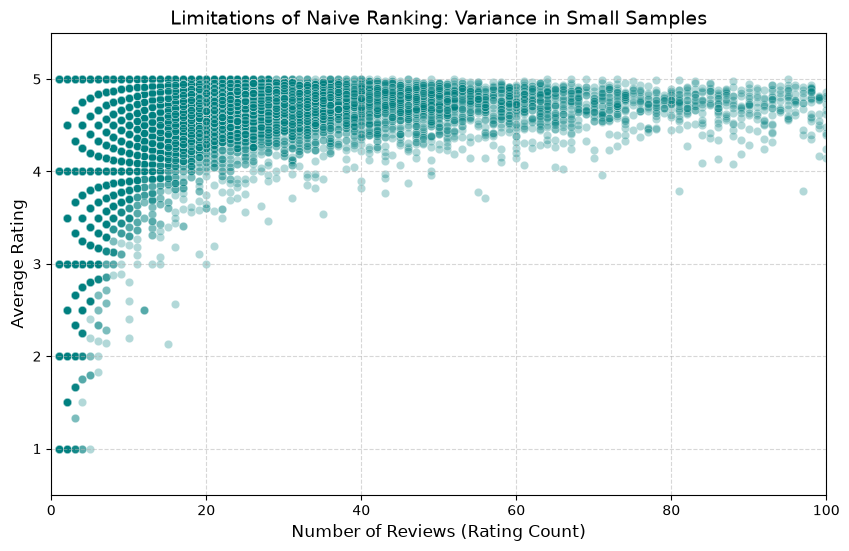

In [38]:
import matplotlib.pyplot as plt
import seaborn as sns

# Limitations of naive ranking
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=ranked_recipes, 
    x='rating_count', 
    y='average_rating', 
    alpha=0.3, 
    color='teal'
)

plt.title('Limitations of Naive Ranking: Variance in Small Samples', fontsize=14)
plt.xlabel('Number of Reviews (Rating Count)', fontsize=12)
plt.ylabel('Average Rating', fontsize=12)

plt.ylim(0.5, 5.5)
plt.xlim(0, 100) # Focus on the first 100 votes to highlight variance

plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [39]:
import pandas as pd

# Create a working copy to analyze rating count volumes
df_analysis = ranked_recipes.copy()

bins = [0, 1, 5, 10, 30, df_analysis['rating_count'].max()]
labels = ['1 vote', '2-5 votes', '6-10 votes', '11-29 votes', '30+ votes']

df_analysis['Rating_bracket'] = pd.cut(df_analysis['rating_count'], bins=bins, labels=labels)

bracket_counts = df_analysis['Rating_bracket'].value_counts().reindex(labels)

print("Overall rating count distribution")
display(bracket_counts)

# Analyze the distribution filtered exclusively for 5.0-star average recipes
perfect_recipes = df_analysis[df_analysis['average_rating'] == 5.0]
perfect_counts = pd.cut(perfect_recipes['rating_count'], bins=bins, labels=labels).value_counts().reindex(labels)

print("\nRating count distribution for 5.0 star recipes")
display(perfect_counts)

Overall rating count distribution


Rating_bracket
1 vote         91698
2-5 votes      94295
6-10 votes     23045
11-29 votes    13594
30+ votes       3958
Name: count, dtype: int64


Rating count distribution for 5.0 star recipes


rating_count
1 vote         59447
2-5 votes      43442
6-10 votes      5837
11-29 votes     1283
30+ votes         39
Name: count, dtype: int64

In [40]:
# Compute the global mean rating across all valid reviews
C = valid_votes['rating'].mean()

# Define confidence threshold (m) using the 90th percentile of rating counts
m = ranked_recipes['rating_count'].quantile(0.90)

print(f"Global mean rating (C): {C:.3f}")
print(f"Confidence threshold (m - 90th percentile): {m:.1f} votes\n")

# Minimum vote threshold 
min_votes = 3
safe_recipes = ranked_recipes[ranked_recipes['rating_count'] >= min_votes].copy()

# Implementation
def calculate_bayesian_score(row):
    v = row['rating_count']
    R = row['average_rating']
    return (v * R + m * C) / (v + m)

safe_recipes['bayesian_score'] = safe_recipes.apply(calculate_bayesian_score, axis=1)

# "Real" top 10 recipes sorted by Bayesian score
bayesian_top10 = safe_recipes.sort_values(by='bayesian_score', ascending=False).head(10)

print("Bayesian top 10 ranking")
display(bayesian_top10[['name', 'bayesian_score', 'average_rating', 'rating_count', 'minutes']])

Global mean rating (C): 4.661
Confidence threshold (m - 90th percentile): 9.0 votes

Bayesian top 10 ranking


,name,bayesian_score,average_rating,rating_count,minutes
12273,bacon lattice tomato muffins rsc,4.984843,5.000000,192,60
131735,mexican stack up rsc,4.977670,4.990783,217,75
55870,company s coming mashed potatoes,4.970707,5.000000,95,40
183472,simply irresistible tropical potato salad sp5,4.962847,5.000000,73,13
115378,kittencal s balsamic vinaigrette,4.960942,5.000000,69,120
206806,the best creole cajun seasoning mix,4.959914,5.000000,67,5
154308,peppered buffalo ranch shrimp pizza rsc,4.958267,5.000000,64,30
215066,uncle bill s method for cooking turkey,4.956269,4.971429,175,330
1047,2 handed kitchen sink tomato sandwich,4.955039,4.987654,81,15
65,never weep whipped cream,4.953488,4.987179,78,5


In [41]:
import numpy as np

# Analyze rating dispersion to identify divisive recipes
rating_dispersion = valid_votes.groupby('recipe_id')['rating'].agg(
    rating_std='std'
).reset_index()

safe_recipes = safe_recipes.drop(columns=['rating_std', 'rating_std_x', 'rating_std_y', 'recipe_id'], errors='ignore').merge(rating_dispersion, left_on='id', right_on='recipe_id', how='left')
safe_recipes['rating_std'] = safe_recipes['rating_std'].fillna(0)

divisive_recipes = safe_recipes[safe_recipes['rating_count'] >= 10].sort_values(
    by='rating_std', ascending=False
).head(5)[['name', 'bayesian_score', 'average_rating', 'rating_std', 'rating_count']]

display(divisive_recipes)

consensus_recipes = safe_recipes[
    (safe_recipes['rating_count'] >= 10) & (safe_recipes['rating_std'] > 0)
].sort_values(
    by=['bayesian_score', 'rating_std'], ascending=[False, True]
).head(5)[['name', 'bayesian_score', 'average_rating', 'rating_std', 'rating_count']]

display(consensus_recipes)

,name,bayesian_score,average_rating,rating_std,rating_count
22667,copycat perkins family restaurant pancakes,3.997674,3.454545,1.967925,11
50291,low low cal angel food cake,4.208078,3.800000,1.932184,10
60158,pancakes for one or two,3.892289,3.200000,1.932184,10
31680,el pollo loco chicken,3.797674,3.090909,1.921174,11
22099,coffee mug cake,3.997552,3.400000,1.897367,10


,name,bayesian_score,average_rating,rating_std,rating_count
53310,mexican stack up rsc,4.977670,4.990783,0.095781,217
85946,uncle bill s method for cooking turkey,4.956269,4.971429,0.167077,175
460,2 handed kitchen sink tomato sandwich,4.955039,4.987654,0.111111,81
37,never weep whipped cream,4.953488,4.987179,0.113228,78
12115,broiled parmesan tilapia low carb,4.949419,4.985915,0.118678,71


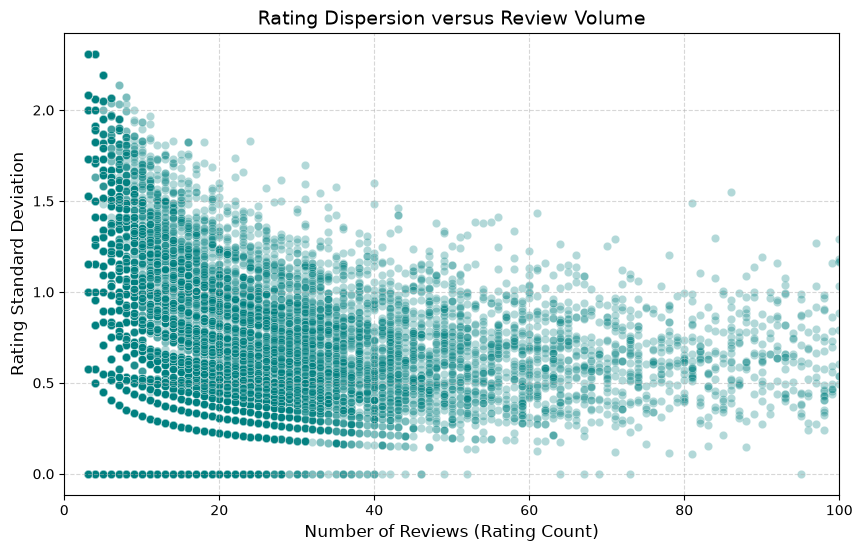

In [42]:
import matplotlib.pyplot as plt
import seaborn as sns

# Dispersion Patterns and Variance Stability in Low-Volume Samples
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=safe_recipes,
    x='rating_count',
    y='rating_std',
    alpha=0.3,
    color='teal'
)

plt.title('Rating Dispersion versus Review Volume', fontsize=14)
plt.xlabel('Number of Reviews (Rating Count)', fontsize=12)
plt.ylabel('Rating Standard Deviation', fontsize=12)

plt.xlim(0, 100) 
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [43]:
# Filter and rank top recipes requiring 30 minutes or less 
fast_recipes = safe_recipes[safe_recipes['minutes'] <= 30]
top_fast = fast_recipes.sort_values(by='bayesian_score', ascending=False).head(5)[
    ['name', 'bayesian_score', 'minutes', 'rating_count']
]

# Filter and rank top recipes requiring max 5 ingredients 
minimal_recipes = safe_recipes[safe_recipes['n_ingredients'] <= 5]
top_minimal = minimal_recipes.sort_values(by='bayesian_score', ascending=False).head(5)[
    ['name', 'bayesian_score', 'n_ingredients', 'rating_count']
]

display("Top fast recipes", top_fast)
display("Top minimalist recipes", top_minimal)

'Top fast recipes'

,name,bayesian_score,minutes,rating_count
73480,simply irresistible tropical potato salad sp5,4.962847,13,73
82603,the best creole cajun seasoning mix,4.959914,5,67
62238,peppered buffalo ranch shrimp pizza rsc,4.958267,30,64
460,2 handed kitchen sink tomato sandwich,4.955039,15,81
37,never weep whipped cream,4.953488,5,78


'Top minimalist recipes'

,name,bayesian_score,n_ingredients,rating_count
73480,simply irresistible tropical potato salad sp5,4.962847,5,73
460,2 handed kitchen sink tomato sandwich,4.955039,4,81
37,never weep whipped cream,4.953488,4,78
67905,refreshing mojito by the pitcher mojitos,4.947422,5,106
2229,animal style skillet potatoes sp5,4.944609,5,46


In [44]:
from collections import Counter
import ast

# Compile the top 20 most frequent tags
def parse_tags(tag_col):
    all_tags = []
    for item in tag_col.dropna():
        if isinstance(item, str):
            try:
                parsed = ast.literal_eval(item)
                all_tags.extend(parsed)
            except (ValueError, SyntaxError) as e:
                print(f"Parsing error: {item}")
        elif isinstance(item, list):
            all_tags.extend(item)
    return all_tags

tag_list = parse_tags(safe_recipes['tags'])
tag_counts = Counter(tag_list)

top_tags = pd.DataFrame(tag_counts.most_common(20), columns=['tag', 'count'])
display(top_tags)

,tag,count
0,preparation,90202
1,time-to-make,88453
2,course,85642
3,dietary,69664
4,main-ingredient,68972
5,easy,50685
6,occasion,47407
7,cuisine,38089
8,low-in-something,35651
9,equipment,33653


In [45]:
# Filter and rank top recipes based on specific tag keywords
def get_top_by_tag(df, tag_keyword):
    filtered_df = df[df['tags_list'].apply(lambda x: isinstance(x, list) and tag_keyword in x)]
    return filtered_df.sort_values(by='bayesian_score', ascending=False).head(5)[
        ['name', 'bayesian_score', 'rating_count', 'average_rating']
    ]

# Query across popular categories
top_main_dishes = get_top_by_tag(safe_recipes, 'main-dish')
top_vegetarian = get_top_by_tag(safe_recipes, 'vegetarian')
top_meat = get_top_by_tag(safe_recipes, 'meat')
top_dietary = get_top_by_tag(safe_recipes, 'dietary')
top_desserts = get_top_by_tag(safe_recipes, 'desserts')

display("Top main dishes", top_main_dishes)
display("Top vegetarian recipes", top_vegetarian)
display("Top meat recipes", top_meat)
display("Top dietary recipes", top_dietary)
display("Top desserts", top_desserts)

'Top main dishes'

,name,bayesian_score,rating_count,average_rating
4944,bacon lattice tomato muffins rsc,4.984843,192,5.000000
53310,mexican stack up rsc,4.977670,217,4.990783
73480,simply irresistible tropical potato salad sp5,4.962847,73,5.000000
85946,uncle bill s method for cooking turkey,4.956269,175,4.971429
12115,broiled parmesan tilapia low carb,4.949419,71,4.985915


'Top vegetarian recipes'

,name,bayesian_score,rating_count,average_rating
46677,kittencal s balsamic vinaigrette,4.960942,69,5.000000
82603,the best creole cajun seasoning mix,4.959914,67,5.000000
46717,kittencal s caesar tortellini salad,4.932300,36,5.000000
73392,simple tomato sandwich,4.927114,170,4.941176
81005,syrup for blueberry pancakes,4.923538,57,4.964912


'Top meat recipes'

,name,bayesian_score,rating_count,average_rating
4944,bacon lattice tomato muffins rsc,4.984843,192,5.000000
53310,mexican stack up rsc,4.977670,217,4.990783
73480,simply irresistible tropical potato salad sp5,4.962847,73,5.000000
85946,uncle bill s method for cooking turkey,4.956269,175,4.971429
67981,rescued turkey stock,4.947974,88,4.977273


'Top dietary recipes'

,name,bayesian_score,rating_count,average_rating
53310,mexican stack up rsc,4.977670,217,4.990783
73480,simply irresistible tropical potato salad sp5,4.962847,73,5.000000
46677,kittencal s balsamic vinaigrette,4.960942,69,5.000000
82603,the best creole cajun seasoning mix,4.959914,67,5.000000
85946,uncle bill s method for cooking turkey,4.956269,175,4.971429


'Top desserts'

,name,bayesian_score,rating_count,average_rating
50867,mag s extra special extra delicious candied pe...,4.940264,42,5.000000
12267,brown sugar bundt cake,4.936139,117,4.957265
57692,oatmeal carmelitas,4.927741,47,4.978723
83386,three not so blind mice,4.924679,58,4.965517
995,absolutely the best new york cheesecake glute...,4.924419,71,4.957746
